# Lesson 4 — Gradient descent: how the machine actually learns

Lesson 4 — Gradient descent: how the machine actually learns
============================================================

GURU NOTE
---------
This is the heart of the whole course. Everything before was setup; everything
after is a variation on this. We have a loss (Lesson 3). We want the weights that
make it smallest. We will NOT guess. We'll compute which direction reduces the
loss and take a small step that way. Repeat a few hundred times. Done.

THE ONE PIECE OF CALCULUS (in plain words)
------------------------------------------
The "gradient" is just the slope of the loss with respect to each weight: "if I
increase this weight a tiny bit, does the loss go up or down, and how fast?" Walk
in the opposite direction (downhill) and the loss drops.

For logistic regression the gradient is famous for being dead simple. For one
weight j it works out to:

        gradient_j = average over all examples of  (p_i - y_i) * x_ij

In words: (what I predicted minus the truth) times (the feature value). If I
over-predicted (p > y) on examples where feature j was large, then weight j is too
high — push it down. That's the entire idea. In matrix form for all weights at
once:

        grad = X.T @ (p - y) / n

Look at train.py lines 43-45. It is LITERALLY this:
        p = sigmoid(x @ w)
        err = (p - y) * sample_w        # sample_w is Lesson 6; ignore for now
        grad = x.T @ err / n

You already understand the real code. Now let's build it.

Run me:  python lessons/lesson_04_gradient_descent.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_04_gradient_descent.py`.

In [2]:
import inspect
from lesson_04_gradient_descent import fit_logistic
for fn in (fit_logistic,):
    print(inspect.getsource(fn)); print('-' * 72)

def fit_logistic(X, y, steps: int = 400, lr: float = 0.5, verbose: bool = True):
    """Train logistic-regression weights by gradient descent.

    This is a stripped-down train.fit_logistic: no regularization (Lesson 5) and
    no class weights (Lesson 6) yet, so the CORE learning loop is unmistakable.
    """
    n, d = X.shape
    w = np.zeros(d)          # start from all-zeros: the model knows nothing
    w[-1] = -0.5             # ...except a mild 'assume benign' bias, like the repo

    for step_i in range(steps):
        p = sigmoid(X @ w)            # 1) predict with current weights
        err = p - y                  # 2) how far off, and which sign
        grad = X.T @ err / n         # 3) THE gradient (derived above)
        step_lr = lr / (1.0 + step_i / 150.0)  # 4) decay: big steps early, small late
        w -= step_lr * grad          # 5) step downhill

        if verbose and step_i in (0, 1, 2, 5, 20, 100, steps - 1):
            print(f"      step {step_i:4d}   loss=

## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

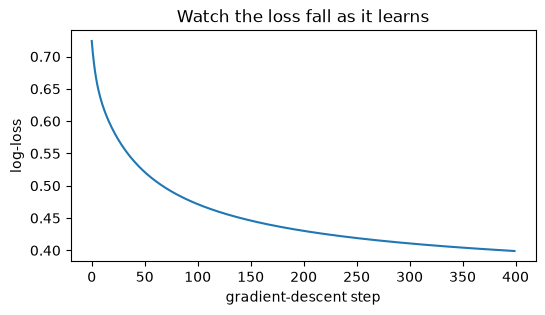

In [3]:
import numpy as np, matplotlib.pyplot as plt
from lesson_01_features import build_dataset
from lesson_02_score_and_sigmoid import add_bias, sigmoid
from lesson_03_loss import log_loss
X, y = build_dataset(); Xb = add_bias(X)
w = np.zeros(Xb.shape[1]); w[-1] = -0.5; hist = []
for i in range(400):
    p = sigmoid(Xb @ w); hist.append(log_loss(y, p))
    w -= (0.5 / (1 + i / 150)) * (Xb.T @ (p - y) / len(y))
plt.figure(figsize=(6, 3)); plt.plot(hist)
plt.xlabel('gradient-descent step'); plt.ylabel('log-loss')
plt.title('Watch the loss fall as it learns'); plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_04_gradient_descent.py`, printing each step with its result.

In [4]:
from lesson_04_gradient_descent import main
main()


═══════════════════════════════════════════════════
Lesson 4 — Gradient descent: how the machine learns
═══════════════════════════════════════════════════

▸ Start from zeros. The model has NO idea. Watch the loss fall.
    Each step: predict -> measure error -> compute gradient -> step down.

      step    0   loss=0.7241   w=[+0.04, +0.07, -0.44]
      step    1   loss=0.7057   w=[+0.08, +0.13, -0.39]
      step    2   loss=0.6906   w=[+0.11, +0.19, -0.35]
      step    5   loss=0.6583   w=[+0.20, +0.35, -0.26]
      step   20   loss=0.5863   w=[+0.55, +0.92, -0.23]
      step  100   loss=0.4715   w=[+1.61, +2.29, -0.64]
      step  399   loss=0.3990   w=[+3.11, +3.60, -1.03]

▸ The learned weights (found automatically, not guessed):
     special_ratio          |███████████████████████████     +3.112
         sqli_hits          |███████████████████████████████ +3.598
              bias █████████|                                -1.025
    Compare to Lesson 2's hand guess [2.0, 4.0, 

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_04_solution.py`.

```
1. Instrument fit_logistic to RECORD the loss at every step into a list, and
   print it every 25 steps. Confirm it decreases monotonically (with a good lr).

2. Set lr=50 and steps=200. What happens to the loss? Explain in one sentence
   what "divergence" looks like and why a too-big step causes it.

3. Remove the bias initialization (start w entirely at zeros). Does the final
   model change much? Why is the starting point less important than the lr here?

4. HARDER: implement gradient checking. Pick weight j, compute the loss at w and
   at w with w[j] nudged by 1e-5, and estimate the slope numerically as
   (loss2 - loss1)/1e-5. Confirm it matches grad[j] from the formula. This is
   how you'd catch a bug in a hand-derived gradient (crucial in Lesson 9).
```

In [5]:
# your work here
